# Integración financiera y macroeconómica: 2005–2025

Unión anual de los archivos procesados de SMV y BCRP, sin modificar sus datos originales ni sus particiones.

**1. Entorno y proteccion de originales**

Se definen rutas y la politica de roles sin consultar valores de prueba. Se registran hashes de entradas, diccionarios, originales raw y notebooks anteriores.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib.metadata as metadata
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "README.md").is_file()
FIN = ROOT / "data/processed/features_financieras.csv"
MAC = ROOT / "data/processed/macroeconomia_peru_2005_2025.csv"
OUT = ROOT / "data/processed/panel_financiero_macroeconomico.csv"
REPORT = ROOT / "reports/validacion_integracion_datos.json"
DIC_MACRO = ROOT / "reports/diccionario_macroeconomia_bcrp.csv"
DIC_FIN = ROOT / "reports/diccionario_features.md"
CATALOGO = ROOT / "reports/diccionario_integracion_datos.csv"
PBI_REFERENCIA = "pbi_real_millones_soles_2007"
ROLES_REQUERIDOS = {PBI_REFERENCIA: "fuente", "inflacion_lima_dic_dic_pct": "predictor",
    "tipo_cambio_promedio_soles_usd": "predictor", "tasa_referencia_promedio_pct": "predictor",
    "crecimiento_pbi_real_pct": "predictor"}
DTYPES_ID = {"RPJ": "string", "RUC": "string"}
ANIOS = pd.Index(range(2005, 2026), name="anio")
protegidos = [FIN, MAC, DIC_MACRO, DIC_FIN, ROOT / "README.md", *sorted(p for p in (ROOT / "data/raw").rglob("*") if p.is_file()), *sorted(p for p in (ROOT / "notebooks").glob("*.ipynb")
               if p.name != "04_integracion_datos.ipynb")]
def huellas():
    return {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in protegidos}
hashes_antes = huellas()
versiones = {p: metadata.version(p) for p in ["pandas", "numpy", "matplotlib", "nbformat", "nbclient"]}
etapas = []
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.25})
print("Python:", platform.python_version())
display(pd.Series(versiones, name="version").to_frame())
etapas.append(1)

Python: 3.12.15


,version
pandas,3.0.6
numpy,2.5.4
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0


El entorno queda identificado y los archivos preexistentes tienen hashes de referencia. La salida utilizará rutas relativas al repositorio.

**2. Carga e inspeccion de entradas**

Se cargan los CSV y el diccionario BCRP preservando identificadores y precision numerica. Se inspeccionan dimensiones, nombres, tipos y cobertura.

In [2]:
fin = pd.read_csv(FIN, dtype=DTYPES_ID, float_precision="round_trip")
macro_original = pd.read_csv(MAC, float_precision="round_trip")
dic_macro = pd.read_csv(DIC_MACRO, dtype="string")
assert {"variable", "codigo", "descripcion", "unidad_final", "metodo", "disponibilidad"}.issubset(dic_macro.columns)
columnas_fin = fin.columns.tolist()
fin_original = fin.copy(deep=True)
dimensiones_entrada = pd.DataFrame([
    {"dataset": "Financiero original", "filas": len(fin), "columnas": fin.shape[1]},
    {"dataset": "BCRP original", "filas": len(macro_original), "columnas": macro_original.shape[1]},
])
display(dimensiones_entrada)
display(pd.concat([fin.dtypes.astype(str).rename("tipo").to_frame().assign(dataset="Financiero"),
                   macro_original.dtypes.astype(str).rename("tipo").to_frame().assign(dataset="BCRP")]).rename_axis("columna"))
assert {"Ejercicio", "RPJ", "objetivo_fcl_t1", "anio_objetivo", "particion"}.issubset(fin.columns)
assert "anio" in macro_original.columns
display(dic_macro[["codigo", "variable", "descripcion", "metodo"]])
display(pd.DataFrame([
    {"dataset": "Financiero", "anio_min": fin.Ejercicio.min(), "anio_max": fin.Ejercicio.max(), "anios": fin.Ejercicio.nunique()},
    {"dataset": "BCRP", "anio_min": macro_original.anio.min(), "anio_max": macro_original.anio.max(), "anios": macro_original.anio.nunique()},
]))
etapas.append(2)

,dataset,filas,columnas
0,Financiero original,4221,57
1,BCRP original,21,6


,tipo,dataset
columna,,
RPJ,string,Financiero
RUC,string,Financiero
NombreEmpresa,str,Financiero
Ejercicio,int64,Financiero
TipoEmpresa,str,Financiero
...,...,...
pbi_real_millones_soles_2007,float64,BCRP
inflacion_lima_dic_dic_pct,float64,BCRP
tipo_cambio_promedio_soles_usd,float64,BCRP


,codigo,variable,descripcion,metodo
0,PM04860AA,pbi_real_millones_soles_2007,"PBI real, millones de soles de 2007",Valor anual original
1,PN38705PM,inflacion_lima_dic_dic_pct,"IPC Lima Metropolitana, diciembre 2021 = 100",100 * (IPC diciembre / IPC diciembre previo - 1)
2,PN01206PM,tipo_cambio_promedio_soles_usd,"Tipo de cambio interbancario venta, promedio m...",Media aritmetica de 12 observaciones mensuales
3,PD04722MM,tasa_referencia_promedio_pct,Tasa de referencia de la politica monetaria,Media aritmetica de 12 observaciones mensuales
4,PM04863AA,crecimiento_pbi_real_pct,Variacion porcentual anual del PBI real,Variacion anual oficial del BCRP; no se infier...


,dataset,anio_min,anio_max,anios
0,Financiero,2005,2025,21
1,BCRP,2005,2025,21


El financiero contiene 4.221 filas y 57 columnas; BCRP contiene 21 filas y seis columnas. El diccionario documenta las cinco series, aunque no incluye la columna de roles mencionada por la auditoria.

**3. Roles y contrato de integracion**

Se incorporan todas las series documentadas: cinco indicadores y su año. El PBI en nivel es referencia; crecimiento, inflacion, cambio y tasa son candidatos predictivos segun roles explicitos.

In [3]:
assert fin.shape == (4221, 57), f"Panel financiero inesperado: {fin.shape}"
assert len(macro_original) == 21, f"Registros BCRP inesperados: {len(macro_original)}"
for tabla, clave in [(fin, "Ejercicio"), (macro_original, "anio")]:
    assert tabla[clave].notna().all() and pd.api.types.is_integer_dtype(tabla[clave]), clave
assert not macro_original.anio.duplicated().any(), "BCRP contiene años duplicados"
assert pd.Index(sorted(macro_original.anio), name="anio").equals(ANIOS)
assert set(fin.Ejercicio).issubset(set(macro_original.anio))
assert fin.RPJ.notna().all()
duplicados_fin_antes = int(fin.duplicated(["RPJ", "Ejercicio"]).sum())
assert duplicados_fin_antes == 0, "Revisar clave financiera original"
assert dic_macro.variable.notna().all() and not dic_macro.variable.duplicated().any()
assert set(dic_macro.variable) == set(ROLES_REQUERIDOS), "El contrato de roles requiere revision"
assert set(macro_original.columns) == {"anio", *dic_macro.variable}, "Inconsistencia fuente/diccionario"
MACRO = [v for v in macro_original.columns if v != "anio"]
dic_macro = dic_macro.set_index("variable").loc[MACRO].reset_index()
roles_en_diccionario_original = "rol_en_dataset" in dic_macro.columns
if roles_en_diccionario_original:
    assert dic_macro.rol_en_dataset.to_dict() == dic_macro.variable.map(ROLES_REQUERIDOS).to_dict()
    origen_roles = "Diccionario BCRP, contrastado con instrucciones de integracion"
else:
    dic_macro["rol_en_dataset"] = dic_macro.variable.map(ROLES_REQUERIDOS)
    origen_roles = "Roles explicitos de la correccion; el diccionario BCRP original no incluye roles"
PREDICTORES_MACRO = dic_macro.loc[dic_macro.rol_en_dataset.eq("predictor"), "variable"].tolist()
REFERENCIAS_MACRO = dic_macro.loc[dic_macro.rol_en_dataset.eq("fuente"), "variable"].tolist()
assert len(PREDICTORES_MACRO) == 4 and REFERENCIAS_MACRO == [PBI_REFERENCIA]
assert "crecimiento_pbi_real_pct" in PREDICTORES_MACRO and PBI_REFERENCIA not in PREDICTORES_MACRO
columnas_excluidas = []
observaciones = []
macro = macro_original[["anio", *MACRO]].copy()
assert macro.shape == (21, 1 + len(dic_macro))
COLUMNAS_ESPERADAS = len(columnas_fin) + len(MACRO)
assert fin.RPJ.nunique() == 336
assert fin.RPJ.str.fullmatch(r"[A-Za-z0-9]{6}", na=False).all()
assert fin.RUC.notna().all() and fin.RUC.str.fullmatch(r"\d+", na=False).all()
ruc_formato_no_11 = ~fin.RUC.str.fullmatch(r"\d{11}", na=False)
ruc_observados = fin.loc[ruc_formato_no_11, ["RPJ", "RUC"]].drop_duplicates()
if ruc_formato_no_11.any():
    observaciones.append(f"RUC de origen con longitud distinta de 11: {int(ruc_formato_no_11.sum())} filas, {len(ruc_observados)} empresas; se conservan sin correccion.")
# Catalogo completo: se heredan sin reinterpretar los roles del diccionario financiero.
filas_dic_fin = [[x.strip() for x in linea.strip().strip("|").split("|")]
                for linea in DIC_FIN.read_text(encoding="utf-8").splitlines() if linea.startswith("| ")]
dic_fin = pd.DataFrame(filas_dic_fin[2:], columns=filas_dic_fin[0])
assert not dic_fin.nombre.duplicated().any() and set(dic_fin.nombre) == set(columnas_fin)
catalogo_fin = dic_fin.rename(columns={"nombre": "variable", "formula": "metodo", "unidad": "unidad_final", "rol": "rol_en_dataset"}).copy()
catalogo_fin["origen"], catalogo_fin["origen_rol"] = "SMV/Feature Engineering", "reports/diccionario_features.md"
catalogo_fin["descripcion"] = catalogo_fin.variable
catalogo_macro = dic_macro.copy()
catalogo_macro["origen"], catalogo_macro["origen_rol"] = "BCRP", origen_roles
catalogo = pd.concat([catalogo_fin, catalogo_macro], ignore_index=True).set_index("variable").loc[columnas_fin + MACRO].reset_index()
catalogo["predictor_candidato"] = catalogo.rol_en_dataset.eq("predictor")
catalogo["funcion_en_panel"] = catalogo.rol_en_dataset.replace({"fuente": "referencia macroeconomica; excluir de seleccion automatica"})
assert catalogo.variable.is_unique and len(catalogo) == COLUMNAS_ESPERADAS
assert catalogo.set_index("variable").loc[PBI_REFERENCIA, "predictor_candidato"] == False
def seleccionar_predictores_macro(catalogo_roles):
    return catalogo_roles.loc[catalogo_roles.origen.eq("BCRP") & catalogo_roles.predictor_candidato, "variable"].tolist()
assert seleccionar_predictores_macro(catalogo) == PREDICTORES_MACRO
assert all(pd.api.types.is_numeric_dtype(macro[v]) for v in MACRO)
assert np.isfinite(macro[MACRO].to_numpy()[macro[MACRO].notna().to_numpy()]).all()
assert not set(MACRO).intersection(columnas_fin), "Colisiones con columnas financieras"
particiones_antes = fin.particion.value_counts(dropna=False).sort_index()
for texto in observaciones:
    print(texto)
display(macro.head())
display(catalogo.loc[catalogo.origen.eq("BCRP"), ["variable", "rol_en_dataset", "predictor_candidato", "metodo"]])
display(particiones_antes.rename("registros_originales").to_frame())
etapas.append(3)

RUC de origen con longitud distinta de 11: 63 filas, 6 empresas; se conservan sin correccion.


,anio,pbi_real_millones_soles_2007,inflacion_lima_dic_dic_pct,tipo_cambio_promedio_soles_usd,tasa_referencia_promedio_pct,crecimiento_pbi_real_pct
0,2005,273971.153887,1.494260,3.297005,3.020833,6.285208
1,2006,294597.830810,1.137485,3.275086,4.291667,7.528777
2,2007,319693.000000,3.927679,3.129229,4.708333,8.518450
3,2008,348870.000045,6.650207,2.927399,5.895833,9.126568
4,2009,352693.000050,0.245316,3.012839,3.250000,1.095824


,variable,rol_en_dataset,predictor_candidato,metodo
57,pbi_real_millones_soles_2007,fuente,False,Valor anual original
58,inflacion_lima_dic_dic_pct,predictor,True,100 * (IPC diciembre / IPC diciembre previo - 1)
59,tipo_cambio_promedio_soles_usd,predictor,True,Media aritmetica de 12 observaciones mensuales
60,tasa_referencia_promedio_pct,predictor,True,Media aritmetica de 12 observaciones mensuales
61,crecimiento_pbi_real_pct,predictor,True,Variacion anual oficial del BCRP; no se infier...


,registros_originales
particion,
entrenamiento,2869
prueba,691
sin_etiqueta_elegible,661


Se integran cinco indicadores: cuatro candidatos predictivos y PBI real como referencia. El catalogo hereda definiciones de los diccionarios y conserva 63 RUC de origen con longitud distinta de 11.

**4. Union izquierda por Ejercicio**

Se aplica una union muchos a uno mediante Ejercicio = anio, sin usar anio_objetivo. Las dimensiones se derivan de las columnas financieras y macroeconomicas reales.

In [4]:
aux_orden, aux_cruce = "__orden_integracion__", "__cruce_integracion__"
assert aux_orden not in fin.columns and aux_cruce not in fin.columns
izquierda = fin.assign(**{aux_orden: np.arange(len(fin))})
derecha = macro.rename(columns={"anio": "Ejercicio"})
cruce = izquierda.merge(derecha, on="Ejercicio", how="left", sort=False,
                       validate="many_to_one", indicator=aux_cruce)
np.testing.assert_array_equal(cruce[aux_orden].to_numpy(), np.arange(len(fin)))
coincidencias = cruce[aux_cruce].value_counts().to_dict()
assert cruce[aux_cruce].eq("both").all(), "Hay ejercicios sin registro BCRP"
integrado = cruce.drop(columns=[aux_orden, aux_cruce])
assert integrado.shape == (len(fin), COLUMNAS_ESPERADAS)
assert integrado.columns.tolist() == columnas_fin + MACRO
assert "anio" not in integrado.columns
assert not any(c.endswith(("_x", "_y")) for c in integrado.columns if c not in columnas_fin)
dimensiones = pd.concat([dimensiones_entrada, pd.DataFrame([
    {"dataset": "BCRP seleccionado", "filas": len(macro), "columnas": macro.shape[1]},
    {"dataset": "Panel integrado", "filas": len(integrado), "columnas": integrado.shape[1]},
])], ignore_index=True)
display(dimensiones)
print("Coincidencias del left join:", coincidencias)
etapas.append(4)

,dataset,filas,columnas
0,Financiero original,4221,57
1,BCRP original,21,6
2,BCRP seleccionado,21,6
3,Panel integrado,4221,62


Coincidencias del left join: {'both': 4221, 'left_only': 0, 'right_only': 0}


La union conserva 4.221 filas y produce 62 columnas: 57 financieras y cinco macroeconomicas. Todos los ejercicios encuentran su registro BCRP, sin duplicar el año.

**5. Conservacion e integridad de identificadores**

Se comparan exactamente las 57 columnas originales, los identificadores y las relaciones RPJ/RUC. Se verifican 336 empresas, objetivo, particiones y ausencia de duplicados nuevos.

In [5]:
pd.testing.assert_frame_equal(integrado[columnas_fin], fin_original, check_exact=True, check_dtype=True)
pd.testing.assert_frame_equal(fin, fin_original, check_exact=True, check_dtype=True)
macro_esperada = macro.set_index("anio")[MACRO].reindex(fin.Ejercicio)
macro_esperada.index = fin.index
pd.testing.assert_frame_equal(integrado[MACRO], macro_esperada, check_exact=True)
duplicados_fin_despues = int(integrado.duplicated(["RPJ", "Ejercicio"]).sum())
assert duplicados_fin_despues == duplicados_fin_antes
particiones_despues = integrado.particion.value_counts(dropna=False).sort_index()
pd.testing.assert_series_equal(particiones_antes, particiones_despues)
pd.testing.assert_series_equal(fin.objetivo_fcl_t1, integrado.objetivo_fcl_t1, check_exact=True)
pd.testing.assert_series_equal(fin.anio_objetivo, integrado.anio_objetivo, check_exact=True)
assert integrado.RPJ.nunique() == 336
pd.testing.assert_frame_equal(integrado[["RPJ", "RUC"]], fin_original[["RPJ", "RUC"]], check_exact=True)
relaciones_antes = fin[["RPJ", "RUC"]].drop_duplicates().reset_index(drop=True)
relaciones_despues = integrado[["RPJ", "RUC"]].drop_duplicates().reset_index(drop=True)
pd.testing.assert_frame_equal(relaciones_antes, relaciones_despues)
assert set(catalogo.variable) == set(integrado.columns)
assert "crecimiento_pbi_real_pct" in integrado
conservacion = pd.DataFrame([
    {"control": "Empresas RPJ", "antes": fin.RPJ.nunique(), "despues": integrado.RPJ.nunique(), "conservado": True},
    {"control": "RUC distintos de origen", "antes": fin.RUC.nunique(), "despues": integrado.RUC.nunique(), "conservado": True},
    {"control": "Filas", "antes": len(fin), "despues": len(integrado), "conservado": len(fin) == len(integrado)},
    {"control": "Columnas financieras exactas", "antes": len(columnas_fin), "despues": len(integrado[columnas_fin].columns), "conservado": True},
    {"control": "Duplicados RPJ/Ejercicio", "antes": duplicados_fin_antes, "despues": duplicados_fin_despues, "conservado": duplicados_fin_antes == duplicados_fin_despues},
    {"control": "Objetivo no nulo", "antes": int(fin.objetivo_fcl_t1.notna().sum()), "despues": int(integrado.objetivo_fcl_t1.notna().sum()), "conservado": True},
])
display(conservacion)
display(pd.concat([particiones_antes.rename("antes"), particiones_despues.rename("despues")], axis=1))
etapas.append(5)

,control,antes,despues,conservado
0,Empresas RPJ,336,336,True
1,RUC distintos de origen,331,331,True
2,Filas,4221,4221,True
3,Columnas financieras exactas,57,57,True
4,Duplicados RPJ/Ejercicio,0,0,True
5,Objetivo no nulo,3607,3607,True


,antes,despues
particion,,
entrenamiento,2869,2869
prueba,691,691
sin_etiqueta_elegible,661,661


Se preservan las 336 empresas, los valores exactos RPJ/RUC y las 57 columnas financieras. Se mantienen 2.869 registros de entrenamiento, 691 de prueba y 661 sin etiqueta elegible.

**6. Cobertura temporal y correspondencia del año**

Se cuenta la cobertura anual y se contrasta cada indicador con su tabla BCRP del mismo año. Se mantiene anio_objetivo como etiqueta temporal y se verifica que no participe en la clave de unión.

In [6]:
cobertura = fin.groupby("Ejercicio").agg(registros_financieros=("RPJ", "size"), empresas=("RPJ", "nunique"))
cobertura["registros_integrados"] = integrado.groupby("Ejercicio").size()
cobertura["registro_bcrp"] = cobertura.index.isin(macro.anio)
cobertura["filas_macro_completas"] = integrado.assign(__completa=integrado[MACRO].notna().all(axis=1)).groupby("Ejercicio")["__completa"].sum()
assert cobertura.registros_financieros.equals(cobertura.registros_integrados.rename("registros_financieros"))
for anio, grupo in integrado.groupby("Ejercicio"):
    esperado = macro.set_index("anio").loc[anio, MACRO]
    for v in MACRO:
        np.testing.assert_array_equal(grupo[v].to_numpy(), np.repeat(esperado[v], len(grupo)))
assert integrado.anio_objetivo.eq(integrado.Ejercicio + 1).all()
resumen_particiones = integrado.groupby("particion", dropna=False).agg(
    registros=("RPJ", "size"), ejercicio_min=("Ejercicio", "min"), ejercicio_max=("Ejercicio", "max"),
    objetivo_min=("anio_objetivo", "min"), objetivo_max=("anio_objetivo", "max"))
display(cobertura)
display(resumen_particiones)
print("Clave verificada: Ejercicio; anio_objetivo se conserva y no se usa para incorporar indicadores.")
etapas.append(6)

,registros_financieros,empresas,registros_integrados,registro_bcrp,filas_macro_completas
Ejercicio,,,,,
2005,194,194,194,True,194
2006,189,189,189,True,189
2007,202,202,202,True,202
2008,207,207,207,True,207
2009,212,212,212,True,212
2010,213,213,213,True,213
2011,216,216,216,True,216
2012,221,221,221,True,221
2013,217,217,217,True,217


,registros,ejercicio_min,ejercicio_max,objetivo_min,objetivo_max
particion,,,,,
entrenamiento,2869,2005,2020,2006,2021
prueba,691,2021,2024,2022,2025
sin_etiqueta_elegible,661,2005,2025,2006,2026


Clave verificada: Ejercicio; anio_objetivo se conserva y no se usa para incorporar indicadores.


Las 4.221 filas reciben indicadores de su propio Ejercicio. Entrenamiento usa ejercicios hasta 2020 y prueba 2021–2024; las particiones se conservaron según sus años objetivo, sin recalcular cortes.

**7. Valores faltantes antes y después de integrar**

Se cuentan faltantes de todas las columnas y se distingue su origen financiero o macroeconómico. Se comprueba que la unión no añade faltantes a las variables financieras ni imputa valores.

In [7]:
faltantes = pd.DataFrame({"tipo": integrado.dtypes.astype(str), "faltantes_despues": integrado.isna().sum()})
faltantes["porcentaje_despues"] = integrado.isna().mean().mul(100)
faltantes["origen"] = np.where(faltantes.index.isin(MACRO), "BCRP", "Financiero")
faltantes["faltantes_antes"] = fin.isna().sum().reindex(integrado.columns).astype("Int64")
faltantes["nuevos_faltantes_financieros"] = (faltantes.faltantes_despues - faltantes.faltantes_antes).astype("Int64")
assert faltantes.loc[columnas_fin, "nuevos_faltantes_financieros"].eq(0).all()
faltantes_macro_origen = macro[MACRO].isna().sum()
faltantes_macro_panel = integrado[MACRO].isna().sum()
display(faltantes.round(2))
display(pd.concat([faltantes_macro_origen.rename("anios_bcrp_faltantes"), faltantes_macro_panel.rename("filas_panel_faltantes")], axis=1))
print("Faltantes financieros conservados:", int(fin.isna().sum().sum()))
print("Faltantes macro en el panel:", int(faltantes_macro_panel.sum()))
etapas.append(7)

,tipo,faltantes_despues,porcentaje_despues,origen,faltantes_antes,nuevos_faltantes_financieros
RPJ,string,0,0.0,Financiero,0,0
RUC,string,0,0.0,Financiero,0,0
NombreEmpresa,str,0,0.0,Financiero,0,0
Ejercicio,int64,0,0.0,Financiero,0,0
TipoEmpresa,str,0,0.0,Financiero,0,0
...,...,...,...,...,...,...
pbi_real_millones_soles_2007,float64,0,0.0,BCRP,<NA>,<NA>
inflacion_lima_dic_dic_pct,float64,0,0.0,BCRP,<NA>,<NA>
tipo_cambio_promedio_soles_usd,float64,0,0.0,BCRP,<NA>,<NA>
tasa_referencia_promedio_pct,float64,0,0.0,BCRP,<NA>,<NA>


,anios_bcrp_faltantes,filas_panel_faltantes
pbi_real_millones_soles_2007,0,0
inflacion_lima_dic_dic_pct,0,0
tipo_cambio_promedio_soles_usd,0,0
tasa_referencia_promedio_pct,0,0
crecimiento_pbi_real_pct,0,0


Faltantes financieros conservados: 20675
Faltantes macro en el panel: 0


Los faltantes financieros se conservan sin imputación ni eliminación de filas. Las cinco variables macroeconómicas no presentan faltantes en los 21 años ni en el panel integrado.

**8. Estadisticas solo de entrenamiento y evolucion**

Los estadisticos se calculan con años unicos de entrenamiento; se verifica su invariancia al alterar prueba. Los graficos completos son descriptivos y no ajustan parametros ni seleccionan predictores.

Estadisticos descriptivos solo de entrenamiento; años: [2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020]


,count,mean,std,min,25%,50%,75%,max
pbi_real_millones_soles_2007,16.0,424967.4991,87444.8759,273971.1539,351737.2500,443817.0000,490527.5001,546605.0001
inflacion_lima_dic_dic_pct,16.0,2.7542,1.5960,0.2453,1.7986,2.4209,3.4081,6.6502
tipo_cambio_promedio_soles_usd,16.0,3.0846,0.2704,2.6383,2.8362,3.1578,3.2902,3.4970
tasa_referencia_promedio_pct,16.0,3.5625,1.1989,0.6667,2.9635,3.8125,4.2344,5.8958
crecimiento_pbi_real_pct,16.0,4.1619,4.7333,-10.9333,2.4847,4.9109,6.6276,9.1266


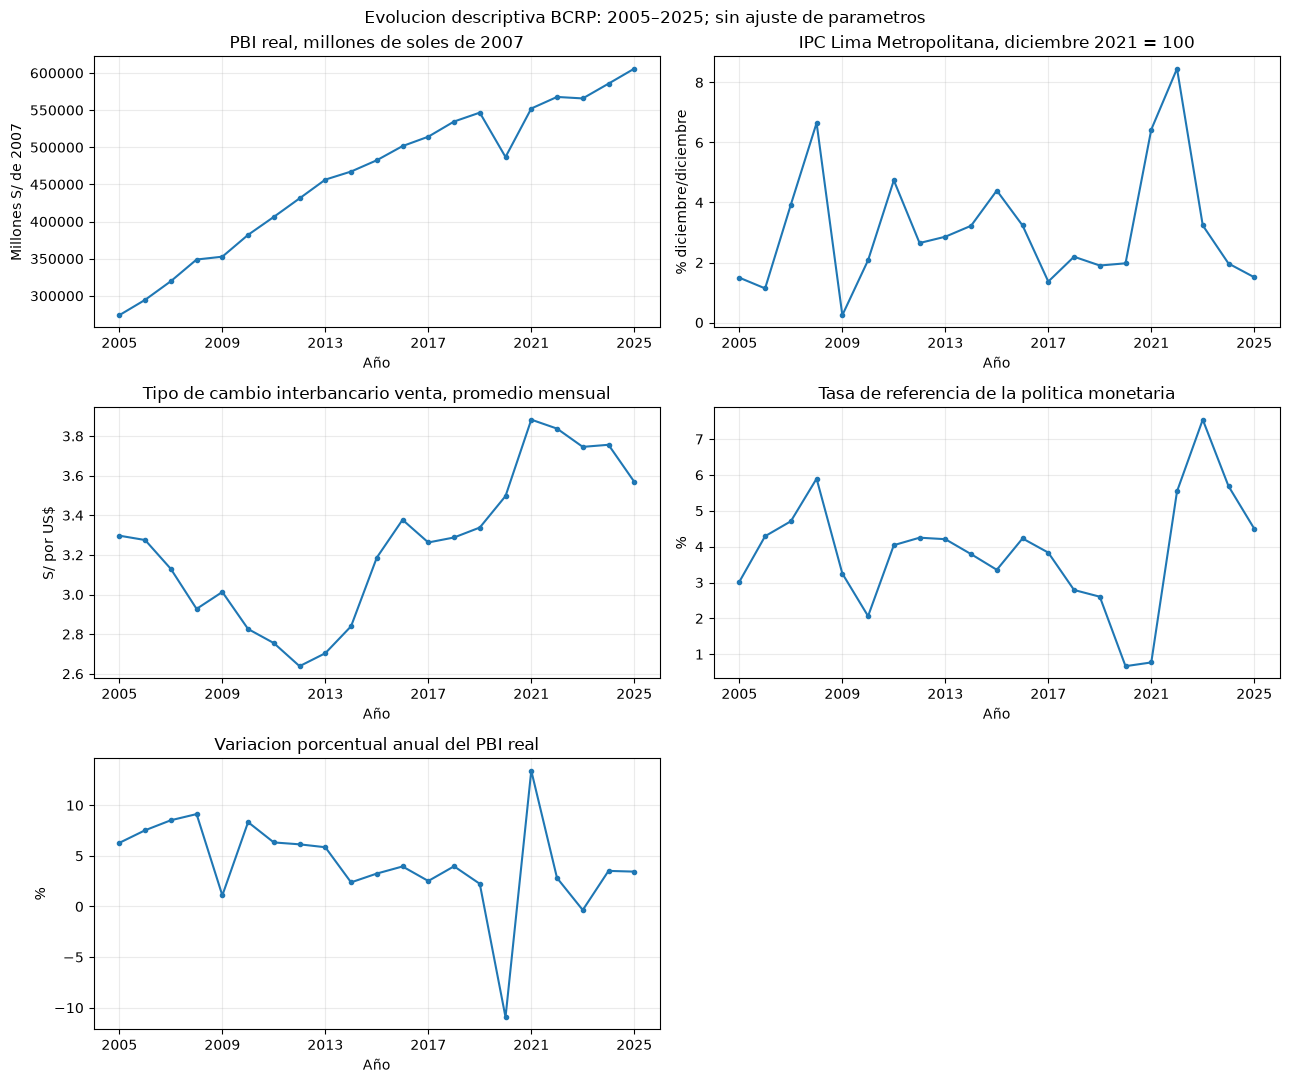

In [8]:
# Las listas proceden del catalogo, no de correlaciones o resultados de prueba.
def estadisticas_entrenamiento(panel, variables):
    historico = panel.loc[panel.particion.eq("entrenamiento"), ["Ejercicio", *variables]]
    assert historico.groupby("Ejercicio")[variables].nunique(dropna=False).le(1).all().all()
    historico = historico.drop_duplicates("Ejercicio").set_index("Ejercicio").sort_index()
    return historico, historico[variables].describe().T
macro_train, descriptivos = estadisticas_entrenamiento(integrado, MACRO)
assert macro_train.index.equals(pd.Index(sorted(fin.loc[fin.particion.eq("entrenamiento"), "Ejercicio"].unique()), name="Ejercicio"))
anios_train = [int(x) for x in macro_train.index]
# Prueba de invariancia: modificar solo prueba no puede cambiar los estadisticos de entrenamiento.
perturbado = integrado.copy(deep=True)
perturbado.loc[perturbado.particion.eq("prueba"), MACRO] = perturbado.loc[perturbado.particion.eq("prueba"), MACRO] * 100 + 1000
train_alterado, estadisticos_alterados = estadisticas_entrenamiento(perturbado, MACRO)
pd.testing.assert_frame_equal(train_alterado, macro_train, check_exact=True)
pd.testing.assert_frame_equal(estadisticos_alterados, descriptivos, check_exact=True)
assert seleccionar_predictores_macro(catalogo) == PREDICTORES_MACRO
print("Estadisticos descriptivos solo de entrenamiento; años:", anios_train)
display(descriptivos.round(4))
unidades = dic_macro.set_index("variable").unidad_final.to_dict()
titulos = dic_macro.set_index("variable").descripcion.to_dict()
fig, axes = plt.subplots(3, 2, figsize=(13, 11))
ordenado = macro.sort_values("anio")
for ax, variable in zip(axes.flat, MACRO):
    ax.plot(ordenado.anio, ordenado[variable], marker="o", markersize=3)
    ax.set(title=titulos[variable], xlabel="Año", ylabel=unidades[variable])
    ax.set_xticks(range(2005, 2026, 4))
axes.flat[-1].set_visible(False)
fig.suptitle("Evolucion descriptiva BCRP: 2005–2025; sin ajuste de parametros")
fig.tight_layout()
plt.show()
etapas.append(8)

Entrenamiento contiene 16 años distintos (2005–2020); sus estadisticos no cambian al perturbar prueba. El crecimiento se conserva como candidato, sin afirmar estacionariedad ni entrenar modelos.

**9. Correspondencia anual y disponibilidad real**

Unir por Ejercicio evita incorporar indicadores del año objetivo, pero no certifica que estuvieran publicados al predecir. Se registran las limitaciones de publicación y revisión sin inventar fechas históricas.

In [9]:
disponibilidad = pd.DataFrame([
    {"variable": MACRO[0], "advertencia": "PBI anual del ejercicio t: requiere cierre y publicacion posterior; las cifras consultadas pueden incorporar revisiones posteriores.", "disponibilidad_fecha_prediccion": "NO VERIFICADA"},
    {"variable": MACRO[1], "advertencia": "IPC de Lima de diciembre: la inflacion anual requiere su publicacion; no equivale a IPC nacional ni a inflacion de IPC medios.", "disponibilidad_fecha_prediccion": "NO VERIFICADA"},
    {"variable": MACRO[2], "advertencia": "Media de 12 promedios mensuales: requiere completar el año y disponer de los registros publicados; no es cierre diario ni promedio diario ponderado.", "disponibilidad_fecha_prediccion": "NO VERIFICADA"},
    {"variable": MACRO[3], "advertencia": "Media de 12 registros mensuales: requiere completar el año; no es tasa efectiva anual ni tasa de cierre.", "disponibilidad_fecha_prediccion": "NO VERIFICADA"},
])
disponibilidad = pd.concat([disponibilidad, pd.DataFrame([{
    "variable": "crecimiento_pbi_real_pct", "advertencia": "Crecimiento anual oficial del PBI: publicacion posterior y posibles revisiones; no se presume estacionariedad.",
    "disponibilidad_fecha_prediccion": "NO VERIFICADA"}])], ignore_index=True)
limitaciones = observaciones + [
    "La union verifica correspondencia con Ejercicio, no disponibilidad historica real de los datos.",
    "Las entradas no incluyen fechas de prediccion, fechas efectivas de publicacion ni versiones historicas disponibles en cada fecha; no se certifica ausencia de fuga por revisiones o publicacion.",
    "PBI en niveles: referencia excluida de predictores automaticos. El crecimiento es candidato; no se ha demostrado estacionariedad ni idoneidad predictiva.",
    "Entrenamiento tiene solo " + str(len(anios_train)) + " años macro distintos; la repeticion por empresa no aumenta la dimension temporal. Validar posteriormente por bloques anuales.",
    "El cambio en niveles puede sufrir desplazamiento de soporte; no se seleccionan transformaciones ni variables usando la particion de prueba.",
    "Se preservan las limitaciones y faltantes del panel financiero de origen; esta integracion no reconstruye ni audita su extraccion historica.",
]
display(disponibilidad)
print("Correspondencia anual: VERIFICADA. Disponibilidad real en fecha de prediccion: NO VERIFICADA.")
etapas.append(9)

,variable,advertencia,disponibilidad_fecha_prediccion
0,pbi_real_millones_soles_2007,PBI anual del ejercicio t: requiere cierre y p...,NO VERIFICADA
1,inflacion_lima_dic_dic_pct,IPC de Lima de diciembre: la inflacion anual r...,NO VERIFICADA
2,tipo_cambio_promedio_soles_usd,Media de 12 promedios mensuales: requiere comp...,NO VERIFICADA
3,tasa_referencia_promedio_pct,Media de 12 registros mensuales: requiere comp...,NO VERIFICADA
4,crecimiento_pbi_real_pct,Crecimiento anual oficial del PBI: publicacion...,NO VERIFICADA


Correspondencia anual: VERIFICADA. Disponibilidad real en fecha de prediccion: NO VERIFICADA.


La clave usa el año de los predictores, sin incorporar el macro de anio_objetivo. La ausencia de fechas y versiones históricas impide certificar un backtest libre de fuga por publicación o revisiones.

**10. Exportacion del panel y catalogo de roles**

Se guardan el panel, el catalogo consolidado y la validacion JSON. Se verifica relectura exacta, coherencia del diccionario y conservacion de originales.

In [10]:
assert etapas == list(range(1, 10)), "Ejecutar desde un kernel limpio en orden"
OUT.parent.mkdir(parents=True, exist_ok=True)
REPORT.parent.mkdir(parents=True, exist_ok=True)
integrado.to_csv(OUT, index=False, encoding="utf-8", na_rep="")
releido = pd.read_csv(OUT, dtype=DTYPES_ID, float_precision="round_trip")
pd.testing.assert_frame_equal(releido, integrado, check_exact=True, check_dtype=True)
pd.testing.assert_frame_equal(releido[columnas_fin], fin_original, check_exact=True, check_dtype=True)
catalogo.to_csv(CATALOGO, index=False, encoding="utf-8", na_rep="")
catalogo_leido = pd.read_csv(CATALOGO, keep_default_na=False)
assert catalogo_leido.variable.tolist() == integrado.columns.tolist()
assert catalogo_leido.loc[catalogo_leido.origen.eq("BCRP") & catalogo_leido.predictor_candidato, "variable"].tolist() == PREDICTORES_MACRO
pd.testing.assert_frame_equal(catalogo_macro.set_index("variable")[dic_macro.columns.drop("variable")],
                              dic_macro.set_index("variable"), check_exact=True)
assert huellas() == hashes_antes, "Un archivo original o notebook anterior fue modificado"
validacion = {
    "estado": "COMPLETADO_CON_OBSERVACIONES", "hallazgos_corregidos": ["IMP-INT-01", "IMP-INT-02"], "verificado_utc": datetime.now(timezone.utc).isoformat(),
    "python": platform.python_version(), "paquetes": versiones,
    "entradas": {str(FIN.relative_to(ROOT)): {"filas": len(fin), "columnas": fin.shape[1]},
                 str(MAC.relative_to(ROOT)): {"filas": len(macro_original), "columnas": macro_original.shape[1]}},
    "esquema_bcrp_conforme_diccionario": macro_original.shape == (21, 1 + len(dic_macro)),
    "columnas_bcrp_esperadas_segun_diccionario": 1 + len(dic_macro),
    "predictores_macroeconomicos": PREDICTORES_MACRO, "referencias_macroeconomicas": REFERENCIAS_MACRO,
    "origen_roles_macro": origen_roles, "roles_presentes_en_diccionario_original": roles_en_diccionario_original,
    "catalogo_integrado": {"archivo": str(CATALOGO.relative_to(ROOT)), "variables": len(catalogo),
        "sha256": hashlib.sha256(CATALOGO.read_bytes()).hexdigest(), "roles_macro": dict(zip(dic_macro.variable, dic_macro.rol_en_dataset))},
    "estadisticos_entrenamiento": {"particion": "entrenamiento", "anios": anios_train, "anios_unicos": len(anios_train),
        "usa_prueba_para_ajuste_o_seleccion": False, "invariancia_ante_perturbacion_prueba": True,
        "seleccion": "Catalogo de roles e instrucciones; sin seleccion empirica usando prueba",
        "descriptivos": json.loads(descriptivos.reset_index(names="variable").to_json(orient="records"))},
    "bcrp_seleccionado": {"filas": len(macro), "columnas": macro.shape[1]},
    "columnas_macro_excluidas": columnas_excluidas, "variables_incorporadas": MACRO,
    "salida": {"archivo": str(OUT.relative_to(ROOT)), "filas": len(releido), "columnas": releido.shape[1],
               "sha256": hashlib.sha256(OUT.read_bytes()).hexdigest()},
    "union": {"tipo": "left", "validacion": "many_to_one", "clave_financiera": "Ejercicio", "clave_bcrp": "anio",
              "usa_anio_objetivo": False, "filas_coincidentes": int(cruce[aux_cruce].eq("both").sum()),
              "filas_sin_coincidencia": int(cruce[aux_cruce].eq("left_only").sum())},
    "controles": {"filas_4221": len(releido) == 4221, "columnas_esperadas": COLUMNAS_ESPERADAS, "dimensiones_correctas": releido.shape == (4221, COLUMNAS_ESPERADAS),
        "empresas_336": releido.RPJ.nunique() == 336, "identificadores_exactos": True,
        "relaciones_rpj_ruc_preservadas": True, "crecimiento_pbi_presente": "crecimiento_pbi_real_pct" in releido,
        "catalogo_coherente": True, "pbi_nivel_excluido_de_predictores": PBI_REFERENCIA not in PREDICTORES_MACRO,
        "columnas_financieras_57_exactas": True, "tipos_y_orden_preservados": True,
        "objetivo_y_anio_objetivo_preservados": True, "particiones_preservadas": True,
        "indicadores_del_mismo_ejercicio": True, "anio_bcrp_unico": True,
        "duplicados_rpj_ejercicio_antes": duplicados_fin_antes, "duplicados_rpj_ejercicio_despues": duplicados_fin_despues,
        "duplicados_generados": duplicados_fin_despues - duplicados_fin_antes, "sin_columna_anio_adicional": "anio" not in releido,
        "relectura_csv_exacta": True, "archivos_preexistentes_preservados": True},
    "particiones_antes": {str(k): int(v) for k, v in particiones_antes.items()},
    "particiones_despues": {str(k): int(v) for k, v in particiones_despues.items()},
    "cobertura_por_ejercicio": json.loads(cobertura.reset_index().to_json(orient="records")),
    "cobertura_particiones": json.loads(resumen_particiones.reset_index().to_json(orient="records")),
    "faltantes_por_columna": {c: int(v) for c, v in integrado.isna().sum().items()},
    "faltantes_financieros_antes": {c: int(v) for c, v in fin.isna().sum().items()},
    "faltantes_macro_origen": {c: int(v) for c, v in faltantes_macro_origen.items()},
    "integridad_identificadores": {"empresas_rpj": int(releido.RPJ.nunique()), "ruc_distintos": int(releido.RUC.nunique()),
        "faltantes_rpj": int(releido.RPJ.isna().sum()), "faltantes_ruc": int(releido.RUC.isna().sum()),
        "filas_ruc_longitud_no_11_origen": int(ruc_formato_no_11.sum()), "relaciones_rpj_ruc_observadas": ruc_observados.to_dict(orient="records"),
        "valores_preservados_exactamente": True},
    "disponibilidad_indicadores": disponibilidad.to_dict(orient="records"),
    "disponibilidad_real_historica": "NO_VERIFICADA", "limitaciones": limitaciones,
    "hashes_archivos_preexistentes": hashes_antes,
    "ejecucion": {"bloques_codigo": 10, "bloques_previos_completados": etapas.copy()},
}
REPORT.write_text(json.dumps(validacion, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8")
assert json.loads(REPORT.read_text(encoding="utf-8")) == validacion
print("Panel guardado:", OUT.relative_to(ROOT), releido.shape)
print("Validacion guardada:", REPORT.relative_to(ROOT))
print("Columnas financieras y archivos originales: conservados exactamente.")
print("Estado:", validacion["estado"])
etapas.append(10)

Panel guardado: data/processed/panel_financiero_macroeconomico.csv (4221, 62)
Validacion guardada: reports/validacion_integracion_datos.json
Columnas financieras y archivos originales: conservados exactamente.
Estado: COMPLETADO_CON_OBSERVACIONES


El panel exportado contiene 4.221 filas y 62 columnas. El catalogo distingue cuatro candidatos macro y una referencia; quedan documentadas las limitaciones de RUC de origen y disponibilidad historica.